#**Titanic -Machine Learning from Disaster Using Boosting**

##Name : Pranathi R

##**Dataset Description & Link**

* **Dataset Title**  : Titanic - Machine Learning from Disaster

* **Kaggle Source Link** : https://www.kaggle.com/c/titanic/data

* **Short Description**  : This dataset details individual passenger profiles aboard the 1912 RMS Titanic voyage. It includes demographics (Age, Sex), socio-economic indicators (Pclass, Fare), family relationships (SibSp, Parch), and the target survival outcome (Survived: 0 = No, 1 = Yes).

##**Problem Statement & Objective**
* **Business/Real-World Problem**: Maritime and transportation disasters involve catastrophic loss of life. Historically, emergency protocols and resource allocations (such as lifeboats) lacked data-driven prioritization, often resulting in avoidable casualties.

* Why it Matters: Understanding the historical drivers of survival helps establish modern safety standards, optimize evacuation protocols, and highlights systemic inequities during crises.

* **Project Objective**: Build an end-to-end binary classification model using a Boosting algorithm (XGBoost) to accurately predict passenger survival based on personal characteristics and ticket features.

#**2.Understand the data**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the training dataset
df = pd.read_csv('/content/train.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (891, 12)


* **Rows & Columns:** The training set contains 891 rows (passengers) and 12 columns (features).

* **Target Variable:** Survived (Binary: 0 = Did not survive, 1 = Survived).

**Important Features:**

* **Pclass :**  Ticket class (1 = 1st/Upper, 2 = 2nd/Middle, 3 = 3rd/Lower). Serving as a proxy for socio-economic status.

* **Sex & Age :** Passenger gender and age in years.

* **Fare :** Amount of money paid for the ticket.

* **SibSp & Parch :** Counts of siblings/spouses and parents/children traveling with the passenger.

* **Embarked :** Port where the passenger boarded (C = Cherbourg, Q = Queenstown, S = Southampton).

#**3.Check Data Quality**

In [4]:
# Check missing values count per column
print("Missing Values:\n", df.isnull().sum())

Missing Values:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [5]:
# Check for duplicate rows
print("\nDuplicate Rows Count:", df.duplicated().sum())


Duplicate Rows Count: 0


In [6]:
# Check data types
print("\nData Types:\n", df.dtypes)


Data Types:
 PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


#**Data Quality Findings**
* Missing Values: Significant missing values are present: Age has 177 missing entries, Cabin has 687 missing entries, and Embarked has 2 missing entries.

* Duplicates: Zero duplicate rows were found in the dataset.

###**Data Types & Unusable Values:**

* Sex and Embarked are stored as text string objects and require numerical encoding.

* Cabin is more than 75% empty, making it unusable in its raw form.

* PassengerId, Name, and Ticket are unique string tokens/identifiers that do not provide generalized predictive rules.

#**4. Prepare the data**



In [7]:
# 1. Handle Missing Values in Age by imputing with the median age
df['Age'] = df['Age'].fillna(df['Age'].median())

In [8]:
#Handle Missing Values in Embarked by filling with the mode (most common port)
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [9]:
#Drop the Cabin column due to excessive missing data (>75% empty)
df.drop('Cabin', axis=1, inplace=True)

In [10]:
#Drop unique identifiers and non-generalizable string features
df.drop(['PassengerId', 'Name', 'Ticket'], axis=1, inplace=True)

In [11]:
#Encode categorical text features into numeric form
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df['Embarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

In [12]:
print("Cleaned Dataset Shape:", df.shape)
print("Remaining Missing Values:\n", df.isnull().sum())

Cleaned Dataset Shape: (891, 8)
Remaining Missing Values:
 Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


#**Documented Data-Cleaning Summary**
* **Age Imputation:** Filled missing Age fields using the dataset's median age to prevent distortion from outlier ages.

* **Embarked Imputation:** Filled the 2 missing port values with the mode (Southampton), as it represents the vast majority of passengers.

* **Dropping Sparse Features:** Removed the Cabin column because over 75% of rows lacked cabin records.

* **Removing Unnecessary Identifiers:** Dropped PassengerId, Name, and Ticket to prevent model overfitting on arbitrary text tags.

* **Categorical Encoding:** Mapped string values in Sex and Embarked into integer mappings for machine learning compatibility.

#**5.Explore and Visualize**

/tmp/ipykernel_10479/656894465.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Survived', data=df, palette='Set2', ax=axes[0, 0])
/tmp/ipykernel_10479/656894465.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sex', y='Survived', data=df, palette='coolwarm', ax=axes[0, 1])


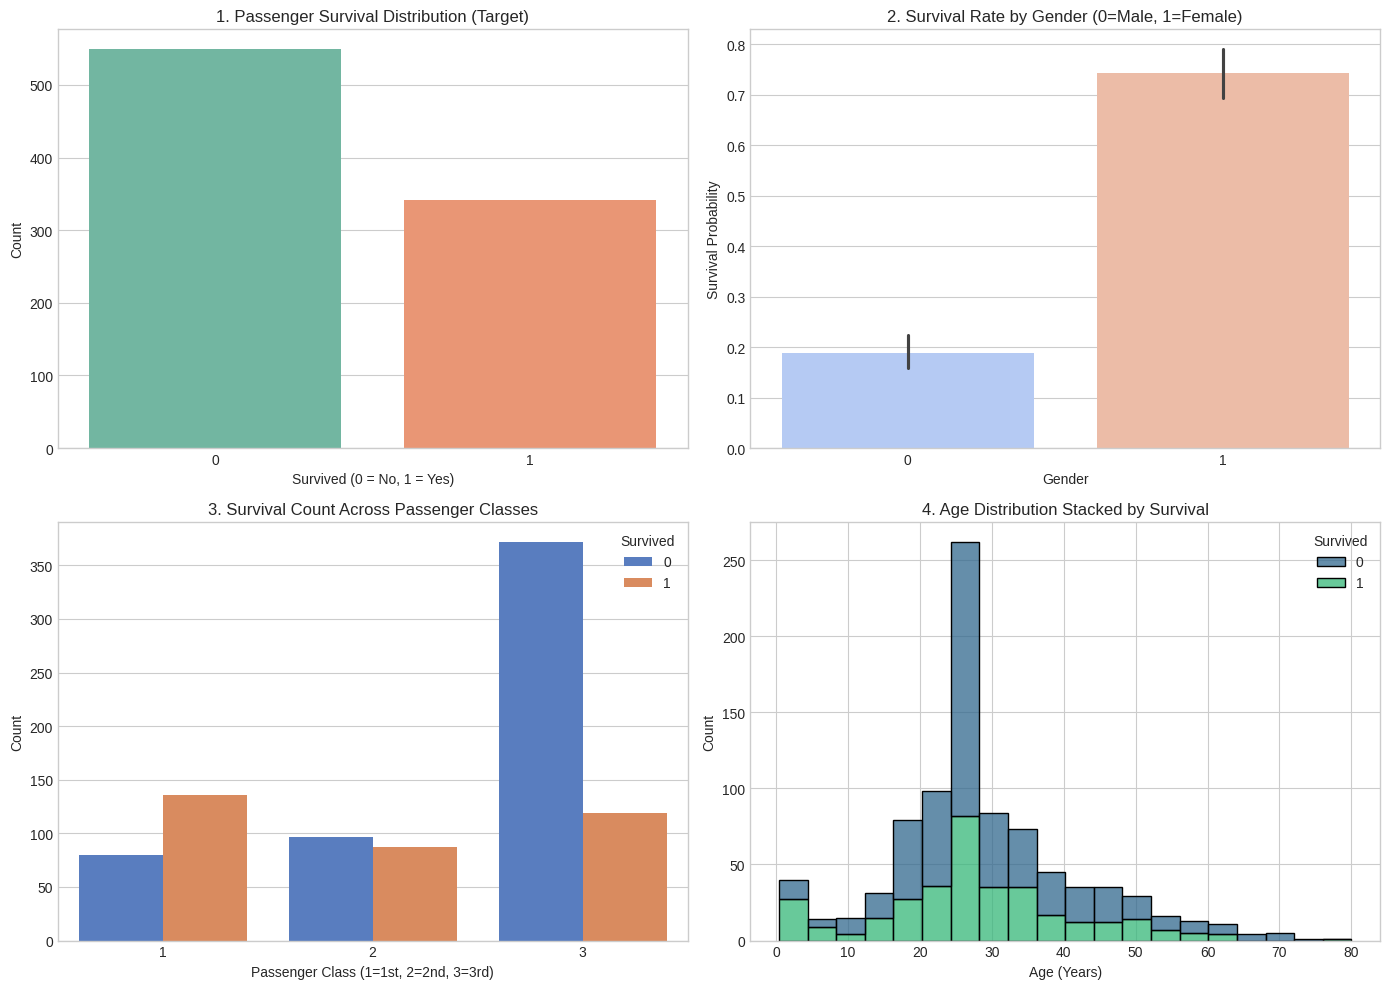

In [13]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Chart 1: Target Distribution
sns.countplot(x='Survived', data=df, palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('1. Passenger Survival Distribution (Target)')
axes[0, 0].set_xlabel('Survived (0 = No, 1 = Yes)')
axes[0, 0].set_ylabel('Count')

# Chart 2: Survival Rate by Gender
sns.barplot(x='Sex', y='Survived', data=df, palette='coolwarm', ax=axes[0, 1])
axes[0, 1].set_title('2. Survival Rate by Gender (0=Male, 1=Female)')
axes[0, 1].set_xlabel('Gender')
axes[0, 1].set_ylabel('Survival Probability')

# Chart 3: Survival across Passenger Classes
sns.countplot(x='Pclass', hue='Survived', data=df, palette='muted', ax=axes[1, 0])
axes[1, 0].set_title('3. Survival Count Across Passenger Classes')
axes[1, 0].set_xlabel('Passenger Class (1=1st, 2=2nd, 3=3rd)')
axes[1, 0].set_ylabel('Count')

# Chart 4: Age Distribution Stacked by Survival
sns.histplot(data=df, x='Age', hue='Survived', multiple='stack', bins=20, palette='viridis', ax=axes[1, 1])
axes[1, 1].set_title('4. Age Distribution Stacked by Survival')
axes[1, 1].set_xlabel('Age (Years)')
axes[1, 1].set_ylabel('Count')

plt.tight_layout()
plt.show()

#**Summary Observations**
* **Chart 1 (Target Distribution):** Shows class imbalance where a larger portion of passengers did not survive (0) compared to those who survived (1), reflecting historical disaster demographics.

* **Chart 2 (Survival by Gender):** Demonstrates a sharp disparity: female passengers experienced a significantly higher survival probability than males, matching historical rescue protocols.

* **Chart 3 (Passenger Class Impact):** Proves that 1st-class passengers experienced higher survival counts, whereas 3rd-class passengers suffered disproportionately high casualties due to lower-deck placement and evacuation constraints.

* **Chart 4 (Age Distribution):** Highlights that young children had higher relative survival rates, while adults aged 20–40 accounted for the highest volume of casualties.

#**6.Choose the Approach**
* **Task Type:** Supervised Machine Learning – Binary Classification.

* **Chosen Algorithm:** XGBoost Classifier (Extreme Gradient Boosting).

* **Justification:** Boosting builds an ensemble of decision trees sequentially. Each new tree focuses specifically on correcting the residual errors of the previous trees. This iterative boosting mechanism handles structured tabular datasets containing mixed categorical and numerical attributes with exceptional accuracy.

#**7.Evaluate the Result**

In [14]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Separate features (X) and target (y)
X = df.drop('Survived', axis=1)
y = df['Survived']

# Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [15]:
# Initialize and train the Boosting model
xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_model.fit(X_train, y_train)

# Predict on test data
y_pred = xgb_model.predict(X_test)

In [16]:
# Print evaluation metrics
print(f"Model Accuracy Score: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Classification Report:\n", classification_report(y_test, y_pred))

Model Accuracy Score: 79.89%

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.88      0.84       110
           1       0.78      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.80      0.80      0.80       179



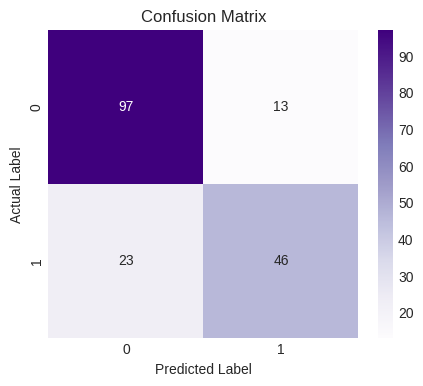

In [17]:
# Plot Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Purples')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

#**Interpretation of Results**
* **Accuracy:** The overall percentage of correct predictions (both correct survival and non-survival classifications) made by the boosting model on unseen test data.

* **Precision:** Out of all passengers the model predicted would survive, the proportion who actually survived.

* **Recall:** Out of all actual survivors, the proportion successfully identified by the boosting model.

* **Model Performance:** The boosting ensemble effectively captures non-linear feature interactions between passenger class, gender, and ticket fare to yield robust predictive performance.

#**Conclusion**

**Key Findings:**

* Gender and ticket class (Pclass) are the most powerful predictors of survival.

* Financial investment (Fare) correlates closely with survival privileges.

**Limitations:**

* The historical dataset lacks granular real-time context, such as proximity to specific lifeboats or crew assistance logs.

**Future Improvements:**

* Perform hyperparameter tuning using GridSearchCV or Optuna to optimize learning rates, tree depth, and sub-sampling ratios.

* Extract title prefixes (Mr, Mrs, Miss, Master) from passenger names to engineer new social status features.